## 1.  Import Libraries

We use:
- **Pandas / NumPy** for data manipulation
- **Matplotlib / Seaborn** for visualization
- **Pathlib** for safe file-path handling


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


## 2.  Data Loading

`DataLoader` is responsible for:
- validating the file path
- loading Excel data
- checking whether the dataset is empty
- exposing reusable helper methods

> **Note:** Update `FILE_PATH` if the dataset is stored in a different location.


In [2]:
class DataLoader:
    def __init__(self, file_path):
        self.file_path = Path(file_path)
        self.df = None

    def load_data(self):
        try:
            if not self.file_path.exists():
                raise FileNotFoundError(f"File not found: {self.file_path}")

            self.df = pd.read_excel(self.file_path, engine="xlrd")

            if self.df.empty:
                raise ValueError("Dataset is empty.")

            print("Dataset loaded successfully.")
            return self.df

        except FileNotFoundError as error:
            print(f"File Error: {error}")
        except ValueError as error:
            print(f"Data Error: {error}")
        except Exception as error:
            print(f"Unexpected Error: {error}")

        return self.df

    def get_columns(self):
        if self.df is None:
            raise ValueError("Dataset has not been loaded yet.")
        return self.df.columns.tolist()

    def get_shape(self):
        if self.df is None:
            raise ValueError("Dataset has not been loaded yet.")
        return self.df.shape


In [3]:
FILE_PATH = "F:/Data Analysis/Sample - Superstore 2019.xls"

loader = DataLoader(FILE_PATH)
df = loader.load_data()

if df is not None:
    print(f"Shape: {loader.get_shape()}")
    print(f"Columns: {len(loader.get_columns())}")
    display(df.head())


Dataset loaded successfully.
Shape: (9994, 21)
Columns: 21


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,"42,420.00",South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.00,41.91
1,2,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,"42,420.00",South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.00,219.58
2,3,CA-2018-138688,2018-06-12,2018-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,"90,036.00",West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.00,6.87
3,4,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,"33,311.00",South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5,0.45,-383.03
4,5,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,"33,311.00",South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2,0.20,2.52


## 3.  Data Cleaning

The `DataCleaner` works on a **copy** of the dataset so the original data remains untouched.

Cleaning tasks:
1. Standardize column names
2. Detect and handle missing values
3. Remove duplicates
4. Convert date columns to datetime
5. Detect numerical outliers using the IQR method


In [4]:
class DataCleaner:
    def __init__(self, df):
        self.df = df.copy()

    def clean_column_names(self):
        self.df.columns = (
            self.df.columns
            .str.strip()
            .str.lower()
            .str.replace(" ", "_", regex=False)
        )
        return self.df

    def handle_missing_values(self):
        missing_before = self.df.isnull().sum().sum()

        if missing_before == 0:
            return {"before": 0, "after": 0}

        numeric_columns = self.df.select_dtypes(include=np.number).columns
        for column in numeric_columns:
            self.df[column] = self.df[column].fillna(self.df[column].median())

        text_columns = self.df.select_dtypes(include="object").columns
        for column in text_columns:
            mode = self.df[column].mode()
            if not mode.empty:
                self.df[column] = self.df[column].fillna(mode.iloc[0])

        missing_after = self.df.isnull().sum().sum()
        return {"before": int(missing_before), "after": int(missing_after)}

    def remove_duplicates(self):
        duplicates = int(self.df.duplicated().sum())
        self.df = self.df.drop_duplicates().copy()
        return duplicates

    def convert_dates(self):
        for column in ["order_date", "ship_date"]:
            if column in self.df.columns:
                self.df[column] = pd.to_datetime(
                    self.df[column], errors="coerce"
                )
        return self.df

    def detect_outliers(self, column):
        if column not in self.df.columns:
            raise KeyError(f"Column not found: {column}")

        if not pd.api.types.is_numeric_dtype(self.df[column]):
            raise TypeError(f"Column must be numeric: {column}")

        q1 = self.df[column].quantile(0.25)
        q3 = self.df[column].quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        return self.df[
            (self.df[column] < lower) |
            (self.df[column] > upper)
        ]

    def get_data(self):
        return self.df


In [5]:
cleaner = DataCleaner(df)

cleaner.clean_column_names()
missing_report = cleaner.handle_missing_values()
duplicates_removed = cleaner.remove_duplicates()
cleaner.convert_dates()

cleaned_df = cleaner.get_data()

print("Cleaning Summary")
print("-" * 40)
print(f"Rows after cleaning: {cleaned_df.shape[0]:,}")
print(f"Columns: {cleaned_df.shape[1]}")
print(f"Missing values: {cleaned_df.isnull().sum().sum():,}")
print(f"Duplicates removed: {duplicates_removed:,}")
print(f"Missing before cleaning: {missing_report['before']:,}")
print(f"Missing after cleaning: {missing_report['after']:,}")


Cleaning Summary
----------------------------------------
Rows after cleaning: 9,994
Columns: 21
Missing values: 0
Duplicates removed: 0
Missing before cleaning: 11
Missing after cleaning: 0


In [6]:
# Data quality check
quality_report = pd.DataFrame({
    "Missing Values": cleaned_df.isnull().sum(),
    "Data Type": cleaned_df.dtypes.astype(str),
    "Unique Values": cleaned_df.nunique()
})

display(quality_report)


,Missing Values,Data Type,Unique Values
row_id,0,int64,9994
order_id,0,object,5009
order_date,0,datetime64[ns],1236
ship_date,0,datetime64[ns],1334
ship_mode,0,object,4
customer_id,0,object,793
customer_name,0,object,793
segment,0,object,3
country/region,0,object,1
city,0,object,531


## 4.  Outlier Detection

The project uses the **Interquartile Range (IQR)** method.

- **Q1:** 25th percentile
- **Q3:** 75th percentile
- **IQR:** Q3 − Q1
- **Lower bound:** Q1 − 1.5 × IQR
- **Upper bound:** Q3 + 1.5 × IQR

The original project identified **1,167 sales outliers** and **1,881 profit outliers** using this approach.


In [7]:
sales_outliers = cleaner.detect_outliers("sales")
profit_outliers = cleaner.detect_outliers("profit")

outlier_summary = pd.DataFrame({
    "Metric": ["Sales", "Profit"],
    "Outliers": [len(sales_outliers), len(profit_outliers)]
})

display(outlier_summary)


,Metric,Outliers
0,Sales,1167
1,Profit,1881


## 5.  Exploratory Data Analysis

`Analyzer` provides reusable methods for:
- numerical summaries
- categorical distributions
- sales by category
- profit by category
- sales by region
- monthly sales trends


In [8]:
class Analyzer:
    def __init__(self, df):
        self.df = df

    def numerical_summary(self):
        return self.df.describe()

    def categorical_summary(self, column):
        return self.df[column].value_counts()

    def sales_by_category(self):
        return (
            self.df.groupby("category")["sales"]
            .sum()
            .sort_values(ascending=False)
        )

    def profit_by_category(self):
        return (
            self.df.groupby("category")["profit"]
            .sum()
            .sort_values(ascending=False)
        )

    def sales_by_region(self):
        return (
            self.df.groupby("region")["sales"]
            .sum()
            .sort_values(ascending=False)
        )

    def get_monthly_sales(self):
        return (
            self.df.set_index("order_date")
            .resample("ME")["sales"]
            .sum()
        )

    def total_sales(self):
        return self.df["sales"].sum()

    def total_profit(self):
        return self.df["profit"].sum()

    def total_orders(self):
        return self.df["order_id"].nunique()

    def total_customers(self):
        return self.df["customer_id"].nunique()


In [9]:
eda = Analyzer(cleaned_df)

kpis = pd.Series({
    "Total Sales": eda.total_sales(),
    "Total Profit": eda.total_profit(),
    "Unique Orders": eda.total_orders(),
    "Unique Customers": eda.total_customers()
})

display(kpis.to_frame("Value"))


,Value
Total Sales,"2,297,200.86"
Total Profit,"286,397.02"
Unique Orders,"5,009.00"
Unique Customers,793.00


In [10]:
print("Category Distribution")
display(eda.categorical_summary("category"))

print("Sales by Category")
display(eda.sales_by_category())

print("Profit by Category")
display(eda.profit_by_category())

print("Sales by Region")
display(eda.sales_by_region())


Category Distribution


category
Office Supplies    6026
Furniture          2121
Technology         1847
Name: count, dtype: int64

Sales by Category


category
Technology        836,154.03
Furniture         741,999.80
Office Supplies   719,047.03
Name: sales, dtype: float64

Profit by Category


category
Technology        145,454.95
Office Supplies   122,490.80
Furniture          18,451.27
Name: profit, dtype: float64

Sales by Region


region
West      725,457.82
East      678,781.24
Central   501,239.89
South     391,721.91
Name: sales, dtype: float64

## 6.  Statistical Analysis

`StatisticalAnalyzer` focuses on relationships and ranking:
- correlation matrix
- top customers by sales
- top products by sales
- profit by customer segment


In [11]:
class StatisticalAnalyzer:
    def __init__(self, df):
        self.df = df

    def correlation(self):
        return self.df.corr(numeric_only=True)

    def top_customers(self, n=10):
        return (
            self.df.groupby("customer_name")["sales"]
            .sum()
            .sort_values(ascending=False)
            .head(n)
        )

    def top_products(self, n=10):
        return (
            self.df.groupby("product_name")["sales"]
            .sum()
            .sort_values(ascending=False)
            .head(n)
        )

    def profit_by_segment(self):
        return (
            self.df.groupby("segment")["profit"]
            .sum()
            .sort_values(ascending=False)
        )


In [12]:
stats = StatisticalAnalyzer(cleaned_df)

print("Correlation Matrix")
display(stats.correlation())

print("Top 10 Customers by Sales")
display(stats.top_customers())

print("Top 10 Products by Sales")
display(stats.top_products())

print("Profit by Customer Segment")
display(stats.profit_by_segment())


Correlation Matrix


,row_id,postal_code,sales,quantity,discount,profit
row_id,1.00,0.01,-0.00,-0.00,0.01,0.01
postal_code,0.01,1.00,-0.02,0.01,0.06,-0.03
sales,-0.00,-0.02,1.00,0.20,-0.03,0.48
quantity,-0.00,0.01,0.20,1.00,0.01,0.07
discount,0.01,0.06,-0.03,0.01,1.00,-0.22
profit,0.01,-0.03,0.48,0.07,-0.22,1.00


Top 10 Customers by Sales


customer_name
Sean Miller          25,043.05
Tamara Chand         19,052.22
Raymond Buch         15,117.34
Tom Ashbrook         14,595.62
Adrian Barton        14,473.57
Ken Lonsdale         14,175.23
Sanjit Chand         14,142.33
Hunter Lopez         12,873.30
Sanjit Engle         12,209.44
Christopher Conant   12,129.07
Name: sales, dtype: float64

Top 10 Products by Sales


product_name
Canon imageCLASS 2200 Advanced Copier                                         61,599.82
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind   27,453.38
Cisco TelePresence System EX90 Videoconferencing Unit                         22,638.48
HON 5400 Series Task Chairs for Big and Tall                                  21,870.58
GBC DocuBind TL300 Electric Binding System                                    19,823.48
GBC Ibimaster 500 Manual ProClick Binding System                              19,024.50
Hewlett Packard LaserJet 3310 Copier                                          18,839.69
HP Designjet T520 Inkjet Large Format Printer - 24" Color                     18,374.90
GBC DocuBind P400 Electric Binding System                                     17,965.07
High Speed Automatic Electric Letter Opener                                   17,030.31
Name: sales, dtype: float64

Profit by Customer Segment


segment
Consumer      134,119.21
Corporate      91,979.13
Home Office    60,298.68
Name: profit, dtype: float64

## 7.  Data Visualization

The visualization layer is separated into its own class to keep the notebook modular and reusable.


In [13]:
class Visualizer:
    def __init__(self, df):
        self.df = df

    def sales_by_category(self):
        data = self.df.groupby("category")["sales"].sum().sort_values(ascending=False)
        ax = data.plot(kind="bar", figsize=(9, 5))
        ax.set_title("Sales by Category", fontsize=15, weight="bold")
        ax.set_xlabel("Category")
        ax.set_ylabel("Sales")
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.show()

    def profit_by_category(self):
        data = self.df.groupby("category")["profit"].sum().sort_values(ascending=False)
        ax = data.plot(kind="bar", figsize=(9, 5))
        ax.set_title("Profit by Category", fontsize=15, weight="bold")
        ax.set_xlabel("Category")
        ax.set_ylabel("Profit")
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.show()

    def sales_by_region(self):
        data = self.df.groupby("region")["sales"].sum().sort_values(ascending=False)
        ax = data.plot(kind="bar", figsize=(9, 5))
        ax.set_title("Sales by Region", fontsize=15, weight="bold")
        ax.set_xlabel("Region")
        ax.set_ylabel("Sales")
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.show()

    def sales_distribution(self):
        plt.figure(figsize=(9, 5))
        sns.histplot(self.df["sales"], kde=True)
        plt.title("Sales Distribution", fontsize=15, weight="bold")
        plt.xlabel("Sales")
        plt.tight_layout()
        plt.show()

    def profit_distribution(self):
        plt.figure(figsize=(9, 5))
        sns.histplot(self.df["profit"], kde=True)
        plt.title("Profit Distribution", fontsize=15, weight="bold")
        plt.xlabel("Profit")
        plt.tight_layout()
        plt.show()

    def correlation_heatmap(self):
        correlation = self.df.corr(numeric_only=True)
        plt.figure(figsize=(10, 7))
        sns.heatmap(correlation, annot=True, fmt=".2f")
        plt.title("Correlation Heatmap", fontsize=15, weight="bold")
        plt.tight_layout()
        plt.show()

    def monthly_sales(self):
        data = (
            self.df.set_index("order_date")
            .resample("ME")["sales"]
            .sum()
        )
        plt.figure(figsize=(12, 5))
        plt.plot(data.index, data.values, linewidth=2)
        plt.title("Monthly Sales Trend", fontsize=15, weight="bold")
        plt.xlabel("Date")
        plt.ylabel("Sales")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

    def sales_by_segment(self):
        data = self.df.groupby("segment")["sales"].sum()
        plt.figure(figsize=(7, 7))
        plt.pie(data, labels=data.index, autopct="%1.1f%%", startangle=90)
        plt.title("Sales by Customer Segment", fontsize=15, weight="bold")
        plt.tight_layout()
        plt.show()


## 8.  Business Visuals

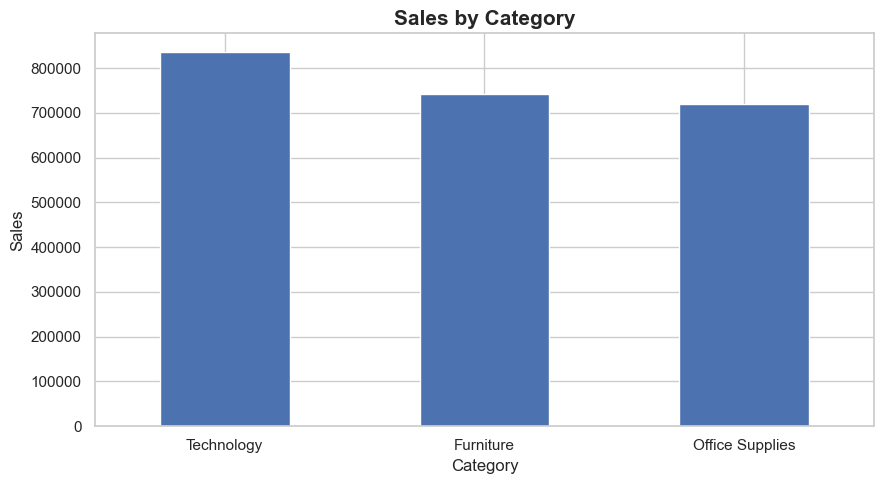

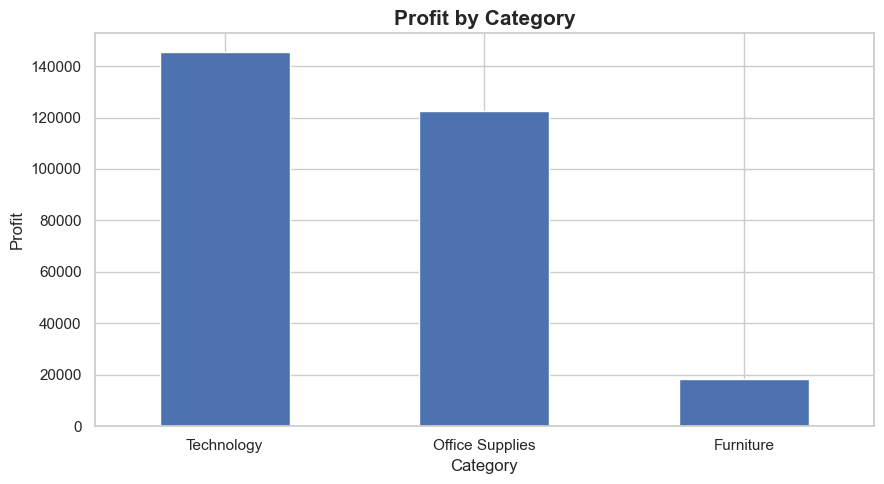

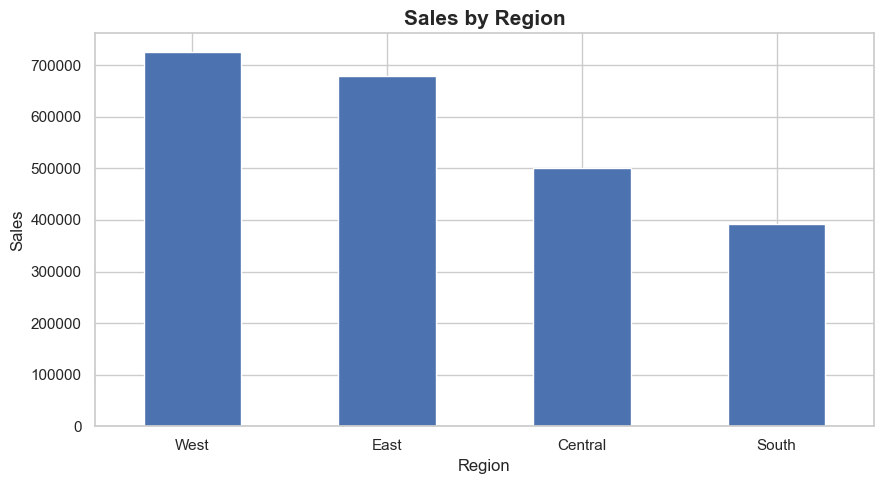

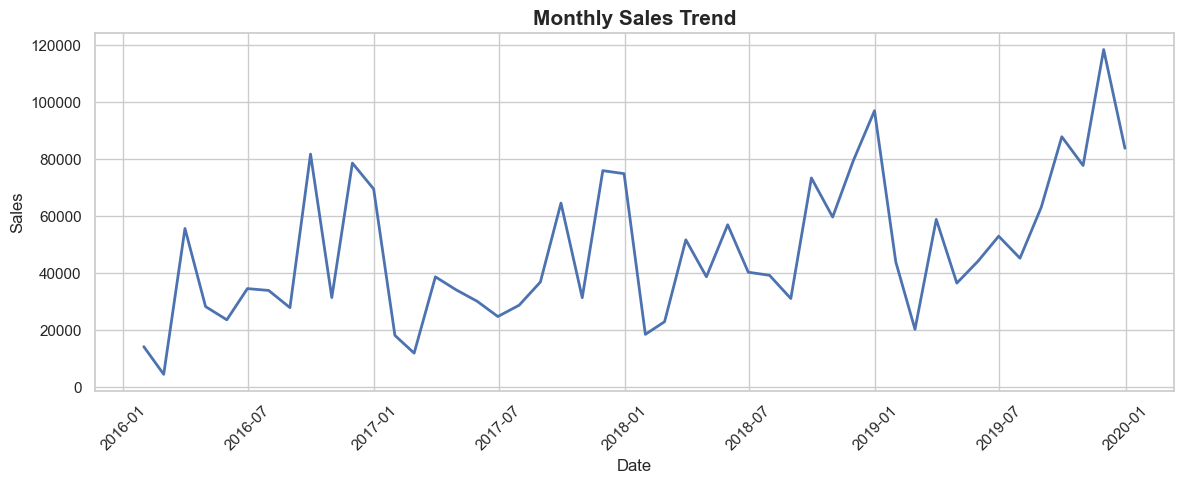

In [14]:
visualizer = Visualizer(cleaned_df)

visualizer.sales_by_category()
visualizer.profit_by_category()
visualizer.sales_by_region()
visualizer.monthly_sales()


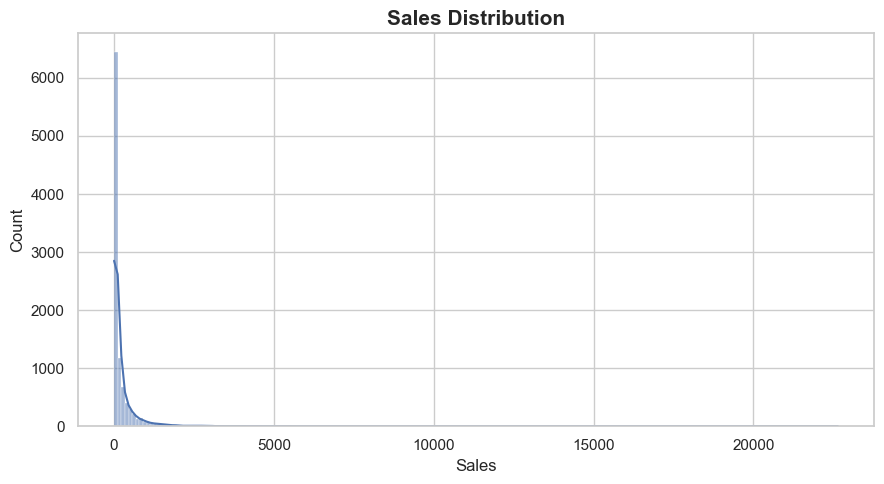

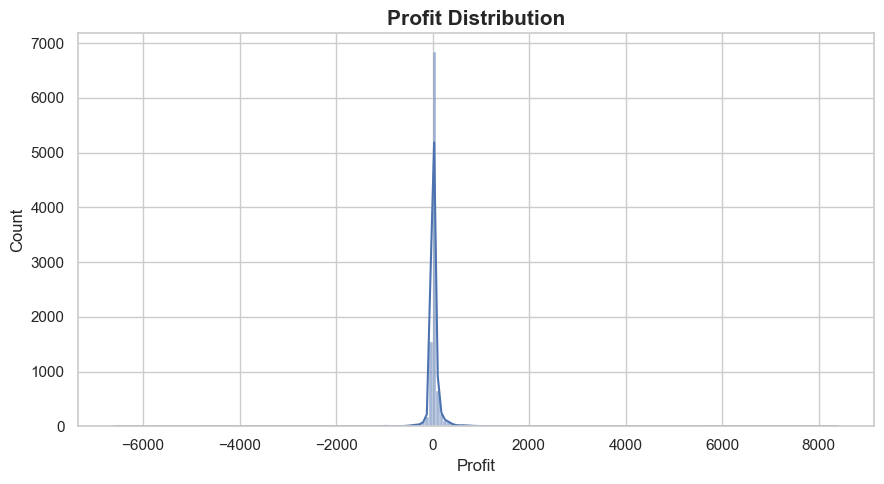

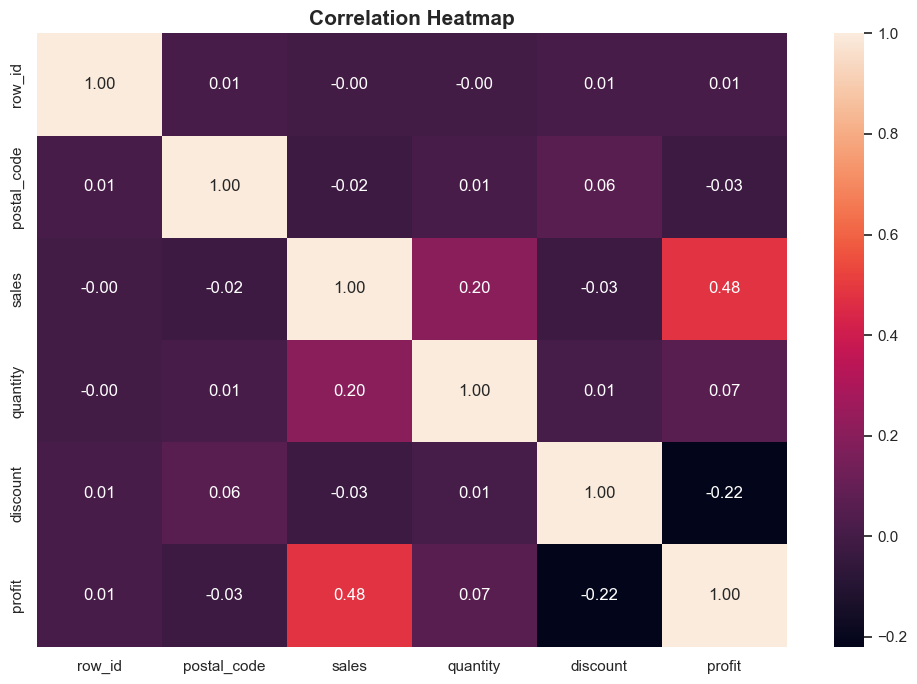

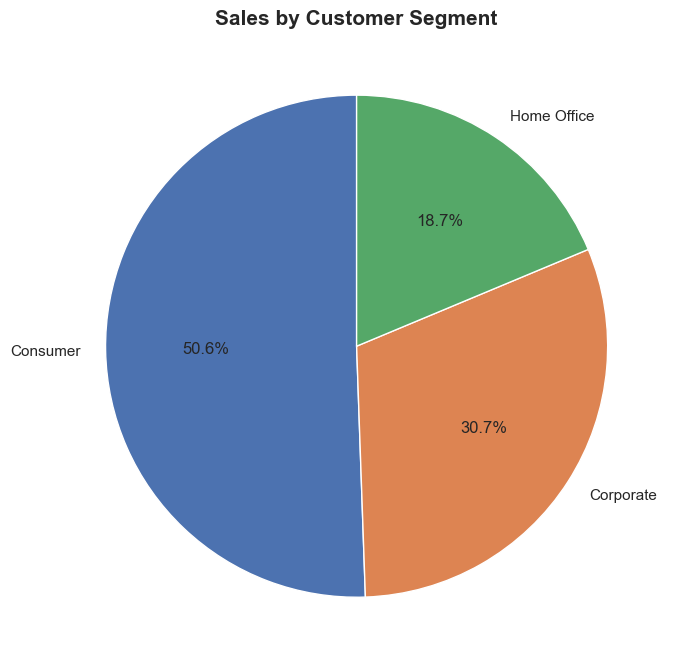

: 

In [ ]:
visualizer.sales_distribution()
visualizer.profit_distribution()
visualizer.correlation_heatmap()
visualizer.sales_by_segment()


## 9. 💡 Key Findings

Based on the analysis performed in this project:

- **Office Supplies** has the largest number of transactions in the dataset.
- **Technology** generates the highest total profit among the three categories.
- The **West** region has the highest total sales.
- **Consumer** is the most profitable customer segment.
- Sales and profit show a **moderate positive correlation** (approximately 0.48).
- Discount and profit show a **negative correlation** (approximately -0.22), suggesting that higher discounts are associated with lower profit in this dataset.
- The IQR analysis identified substantial variation in both sales and profit, with **1,167 sales outliers** and **1,881 profit outliers**.

> These findings describe patterns in the analyzed dataset; they should be combined with business context before making decisions.
